--- RINGKASAN DESKRIPTIF KATALOG ---
Rentang Waktu: 2020-01-01 00:00:00 sampai 2021-05-14 00:00:00
Total Kejadian Gempa: 500 event
Batas Wilayah (Lintang): -9.92 hingga 4.89
Batas Wilayah (Bujur): 95.21 hingga 140.99
       Kedalaman_km   Magnitudo
count    500.000000  500.000000
mean      32.411786    5.737668
std       32.472230    1.004534
min        0.148567    4.011264
25%        8.281672    4.843760
50%       23.278808    5.781120
75%       45.064295    6.580817
max      223.251687    7.494216


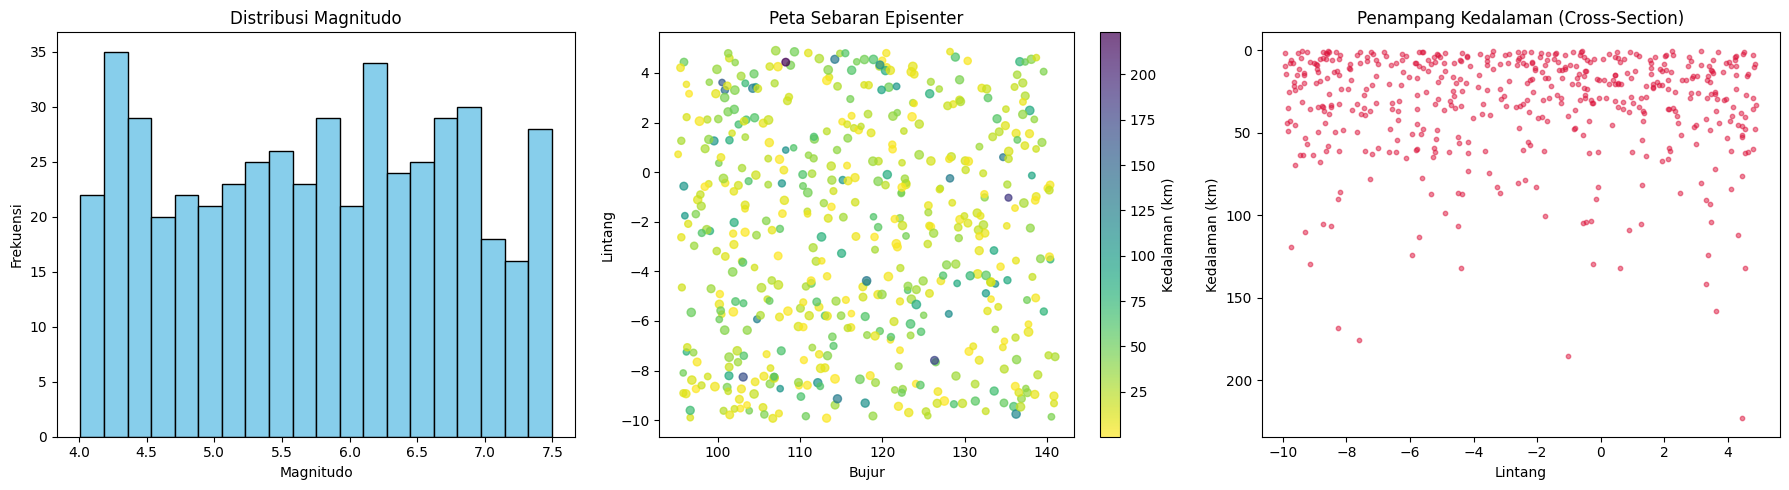

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Contoh pembuatan DataFrame tiruan untuk simulasi katalog gempa
# (Ganti dengan pd.read_csv('katalog_gempa.csv') untuk data riil Anda)
np.random.seed(42)
n_events = 500
data = {
    'Waktu': pd.date_range(start='2020-01-01', periods=n_events, freq='D'),
    'Lintang': np.random.uniform(-10.0, 5.0, n_events),
    'Bujur': np.random.uniform(95.0, 141.0, n_events),
    'Kedalaman_km': np.random.exponential(scale=30.0, size=n_events),
    'Magnitudo': np.random.uniform(4.0, 7.5, n_events),
}
df_gempa = pd.DataFrame(data)

# 1. Ringkasan Deskriptif Katalog
print('--- RINGKASAN DESKRIPTIF KATALOG ---')
print(f"Rentang Waktu: {df_gempa['Waktu'].min()} sampai {df_gempa['Waktu'].max()}")
print(f"Total Kejadian Gempa: {len(df_gempa)} event")
print(f"Batas Wilayah (Lintang): {df_gempa['Lintang'].min():.2f} hingga {df_gempa['Lintang'].max():.2f}")
print(f"Batas Wilayah (Bujur): {df_gempa['Bujur'].min():.2f} hingga {df_gempa['Bujur'].max():.2f}")
print(df_gempa[['Kedalaman_km', 'Magnitudo']].describe())

# 2. Visualisasi: Distribusi Magnitudo & Penampang Kedalaman (Cross-Section)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram Magnitudo
axes[0].hist(df_gempa['Magnitudo'], bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Distribusi Magnitudo')
axes[0].set_xlabel('Magnitudo')
axes[0].set_ylabel('Frekuensi')

# Sebaran Spasial (Peta Episenter)
sc = axes[1].scatter(
    df_gempa['Bujur'],
    df_gempa['Lintang'],
    c=df_gempa['Kedalaman_km'],
    cmap='viridis_r',
    s=df_gempa['Magnitudo'] * 5,
    alpha=0.7,
)
axes[1].set_title('Peta Sebaran Episenter')
axes[1].set_xlabel('Bujur')
axes[1].set_ylabel('Lintang')
plt.colorbar(sc, ax=axes[1], label='Kedalaman (km)')

# Penampang Kedalaman (Lintang vs Kedalaman)
axes[2].scatter(
    df_gempa['Lintang'],
    df_gempa['Kedalaman_km'],
    c='crimson',
    alpha=0.5,
    s=10,
)
axes[2].set_title('Penampang Kedalaman (Cross-Section)')
axes[2].set_xlabel('Lintang')
axes[2].set_ylabel('Kedalaman (km)')
axes[2].invert_yaxis()  # Kedalaman bertambah ke bawah

plt.tight_layout()
plt.show()

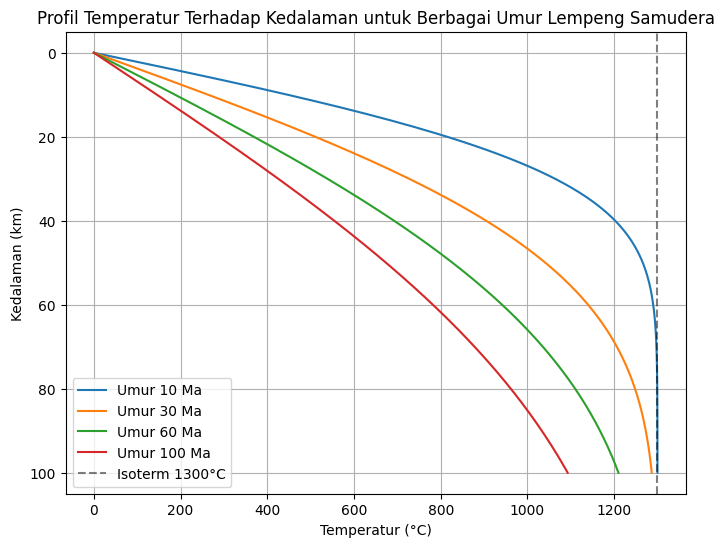

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Parameter Fisika & Konstanta
T_surface = 0.0  # Suhu permukaan (°C)
T_mantle = 1300.0  # Suhu mantel/astenosfer (°C)
kappa = 8.0e-7  # Difusivitas termal (m^2/s)
sec_in_myr = 1e6 * 365.25 * 24 * 3600  # Konversi Juta Tahun ke Detik

# Kedalaman (z) dalam meter (0 hingga 100 km)
z = np.linspace(0, 100000, 200)

# Variasi Umur Lempeng (dalam Juta Tahun / Ma)
ages_ma = [10, 30, 60, 100]

plt.figure(figsize=(8, 6))

for age_ma in ages_ma:
  t = age_ma * sec_in_myr
  # Solusi Analitik Half-Space Cooling Model (Fungsi Error / erf)
  from scipy.special import erf

  T = T_surface + (T_mantle - T_surface) * erf(z / (2 * np.sqrt(kappa * t)))
  plt.plot(T, z / 1000, label=f'Umur {age_ma} Ma')

plt.title(
    'Profil Temperatur Terhadap Kedalaman untuk Berbagai Umur Lempeng Samudera'
)
plt.xlabel('Temperatur (°C)')
plt.ylabel('Kedalaman (km)')
plt.gca().invert_yaxis()  # Membalik sumbu y agar kedalaman bertambah ke bawah
plt.axvline(
    1300, color='black', linestyle='--', alpha=0.5, label='Isoterm 1300°C'
)
plt.legend()
plt.grid(True)
plt.show()

--- PARAMETER VARIOGRAM ---
Nugget Effect: 0
Sill: 0.9171306734810385
Range: 38.53558356337632


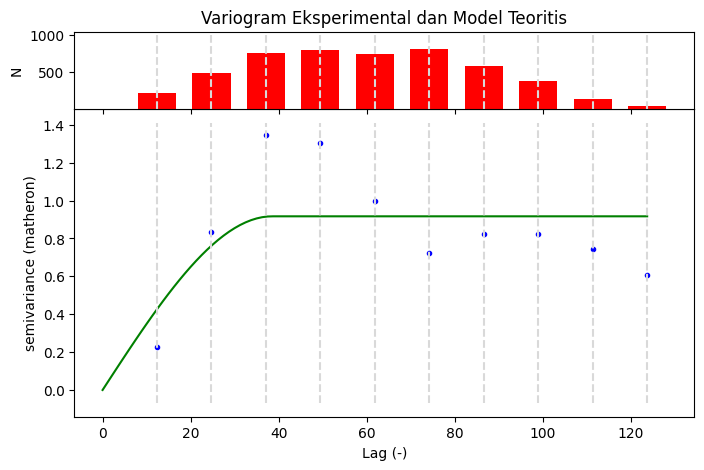

In [15]:
!pip install scikit-gstat

import matplotlib.pyplot as plt
import numpy as np
import skgstat as skg

# Membuat data koordinat dan nilai atribut tiruan (misal: Anomali Gayaberat)
np.random.seed(42)
coords = np.random.rand(100, 2) * 100  # Koordinat X, Y dalam km
values = (
    np.sin(coords[:, 0] / 10) + np.cos(coords[:, 1] / 10) + np.random.normal(0, 0.2, 100)
)

# Menghitung Variogram Eksperimental
V = skg.Variogram(
    coords, values, estimator='matheron', n_lags=10, model='spherical'
)

# Menampilkan Parameter Variogram menggunakan properti .parameters (urutan: [range, sill, nugget])
print('--- PARAMETER VARIOGRAM ---')
params = V.parameters
print(f'Nugget Effect: {params[2]}')
print(f'Sill: {params[1]}')
print(f'Range: {params[0]}')

# Plot Variogram Eksperimental & Model Teoritis
V.plot()
plt.title('Variogram Eksperimental dan Model Teoritis')
plt.show()

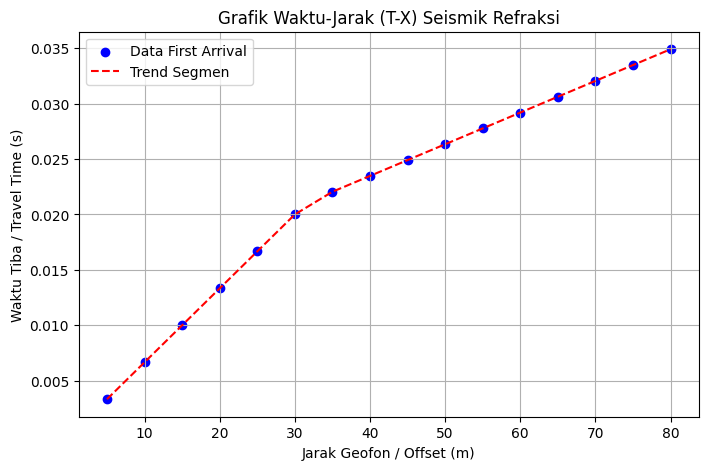

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data Waktu-Jarak (X dalam meter, T dalam sekon)
jarak_x = np.array(
    [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80]
)
# Simulasi waktu tempuh dua lapisan
v1 = 1500.0  # Kecepatan lapisan 1 (m/s)
v2 = 3500.0  # Kecepatan lapisan 2 (m/s)
h1 = 10.0  # Ketebalan lapisan 1 (m)

# Perhitungan waktu tempuh teoretis
waktu_t = np.where(
    jarak_x < 2 * h1 * np.sqrt((v2 + v1) / (v2 - v1)),
    jarak_x / v1,
    (jarak_x / v2) + (2 * h1 * np.sqrt(v2**2 - v1**2) / (v1 * v2)),
)

# Plot Kurva T-X
plt.figure(figsize=(8, 5))
plt.scatter(jarak_x, waktu_t, color='blue', label='Data First Arrival')
plt.plot(jarak_x, waktu_t, color='red', linestyle='--', label='Trend Segmen')
plt.title('Grafik Waktu-Jarak (T-X) Seismik Refraksi')
plt.xlabel('Jarak Geofon / Offset (m)')
plt.ylabel('Waktu Tiba / Travel Time (s)')
plt.grid(True)
plt.legend()
plt.show()

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GroupKFold, train_test_split

# 1. Simulasi Dataset Log Sumur
np.random.seed(42)
n_samples = 1000
df_log = pd.DataFrame({
    'Well_ID': np.random.choice(['Sumur_A', 'Sumur_B', 'Sumur_C', 'Sumur_D'], n_samples),
    'Depth': np.sort(np.random.uniform(1000, 3500, n_samples)),
    'Gamma_Ray': np.random.uniform(20, 150, n_samples),
    'Density': np.random.uniform(2.0, 2.8, n_samples),
    'Sonic': np.random.uniform(50, 140, n_samples),
})

# Membuat label litologi sintetik berdasarkan aturan sederhana
conditions = [
    (df_log['Gamma_Ray'] < 50) & (df_log['Density'] > 2.5),  # Batugamping
    (df_log['Gamma_Ray'] >= 50) & (df_log['Gamma_Ray'] < 90), # Batupasir
    (df_log['Gamma_Ray'] >= 90),                            # Serpih (Shale)
]
choices = ['Batugamping', 'Batupasir', 'Serpih']
df_log['Litologi'] = np.select(conditions, choices, default='Batupasir')

# 2. Persiapan Fitur & Target (Fitur Depth dan Well_ID TIDAK dimasukkan sebagai prediktor)
X = df_log[['Gamma_Ray', 'Density', 'Sonic']]
y = df_log['Litologi']

# 3. Pembagian Data Berbasis Sumur (Well-based split untuk mencegah data leakage)
train_wells, test_wells = train_test_split(df_log['Well_ID'].unique(), test_size=0.25, random_state=42)
train_idx = df_log['Well_ID'].isin(train_wells)
test_idx = ~train_idx

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

# 4. Pelatihan Model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 5. Evaluasi Performa Model
y_pred = rf_model.predict(X_test)
print('--- LAPORAN KLASIFIKASI LITOLOGI ---')
print(classification_report(y_test, y_pred))

--- LAPORAN KLASIFIKASI LITOLOGI ---
              precision    recall  f1-score   support

 Batugamping       1.00      0.96      0.98        26
   Batupasir       0.99      1.00      1.00       128
      Serpih       1.00      1.00      1.00       126

    accuracy                           1.00       280
   macro avg       1.00      0.99      0.99       280
weighted avg       1.00      1.00      1.00       280

